<a href="https://colab.research.google.com/github/erikarahmadinaaa01/202431176_Erika-Rahmadina_F/blob/main/Erika_Rahmadina_202431176_Laporan1_SUPERVISED_D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**IMPORT LIBRARY**

In [2]:
# 202431176_Erika Rahmadina
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

**DATA COLLECTING FROM KAGGLE**

In [3]:
# 202431176_Erika Rahmadina
df_xlsx = pd.read_excel('Erika Rahmadina_202431176_Laporan1_SUPERVISED_D.xlsx')
print("Data Excel Cosmetics:")
display(df_xlsx.head())

Data Excel Cosmetics:


,Sales Person,Country,Product,Date,Amount ($),Boxes Shipped
0,Lucas Verma,Canada,Aloe Vera Gel,2022-04-30,7897.13,358
1,Ethan Reddy,UK,Aloe Vera Gel,2022-01-25,16376.88,449
2,Ananya Gupta,India,Body Butter Cream,2022-08-22,5599.68,264
3,Ananya Gupta,New Zealand,Salicylic Acid Cleanser,2022-08-26,2966.47,144
4,Sophia Nair,UK,Body Butter Cream,2022-05-19,6828.68,484


**PROSES EDA**

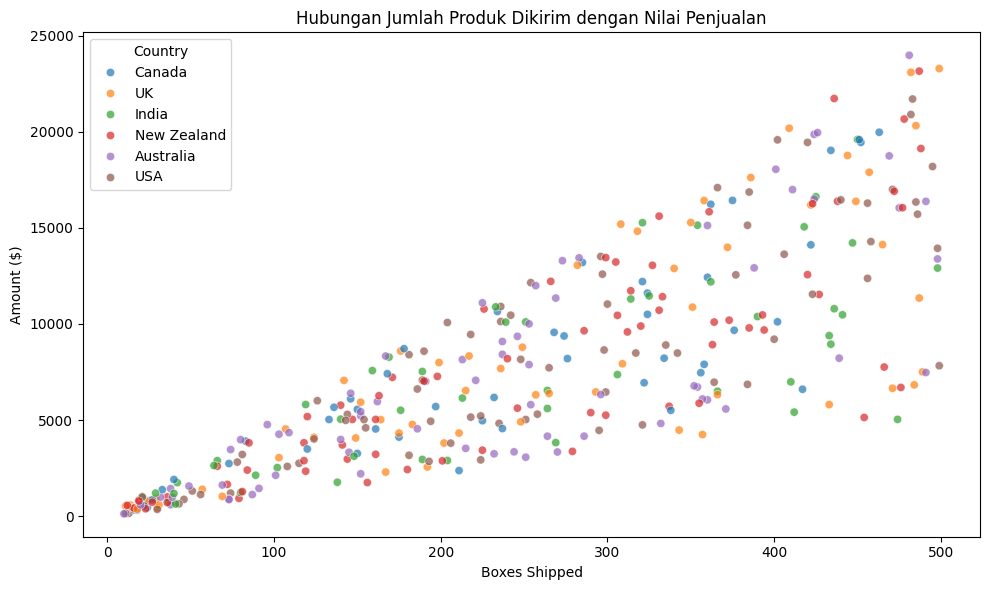

In [4]:
# 202431176_Erika Rahmadina
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_xlsx,
    x='Boxes Shipped',
    y='Amount ($)',
    hue='Country',
    alpha=0.7
)

plt.title('Hubungan Jumlah Produk Dikirim dengan Nilai Penjualan')
plt.xlabel('Boxes Shipped')
plt.ylabel('Amount ($)')
plt.legend(title='Country')
plt.tight_layout()
plt.show()

**PREPOCESSING**

1. Memeriksa kondisi awal data

In [5]:
# 202431176_Erika Rahmadina
# Memeriksa ukuran dataset
print("Ukuran dataset:", df_xlsx.shape)

# Memeriksa tipe data
print("\nTipe Data:")
print(df_xlsx.dtypes)

# Memeriksa missing values
print("\nMissing Values:")
print(df_xlsx.isnull().sum())

# Memeriksa data duplikat
print("\nJumlah Data Duplikat:")
print(df_xlsx.duplicated().sum())

Ukuran dataset: (374, 6)

Tipe Data:
Sales Person             object
Country                  object
Product                  object
Date             datetime64[ns]
Amount ($)              float64
Boxes Shipped             int64
dtype: object

Missing Values:
Sales Person     0
Country          0
Product          0
Date             0
Amount ($)       0
Boxes Shipped    0
dtype: int64

Jumlah Data Duplikat:
0


2. Memastikan tipe data dan konsistensi

In [6]:
# 202431176_Erika Rahmadina
# Membuat salinan dataset
df_clean = df_xlsx.copy()

# Memastikan format tanggal
df_clean['Date'] = pd.to_datetime(
    df_clean['Date'],
    errors='coerce'
)

# Memastikan kolom numerik
df_clean['Amount ($)'] = pd.to_numeric(
    df_clean['Amount ($)'],
    errors='coerce'
)

df_clean['Boxes Shipped'] = pd.to_numeric(
    df_clean['Boxes Shipped'],
    errors='coerce'
)

# Menghapus spasi berlebih pada kolom teks
kolom_teks = ['Sales Person', 'Country', 'Product']

for kolom in kolom_teks:
    df_clean[kolom] = df_clean[kolom].str.strip()

print("Tipe data setelah preprocessing:")
print(df_clean.dtypes)

display(df_clean.head())

Tipe data setelah preprocessing:
Sales Person             object
Country                  object
Product                  object
Date             datetime64[ns]
Amount ($)              float64
Boxes Shipped             int64
dtype: object


,Sales Person,Country,Product,Date,Amount ($),Boxes Shipped
0,Lucas Verma,Canada,Aloe Vera Gel,2022-04-30,7897.13,358
1,Ethan Reddy,UK,Aloe Vera Gel,2022-01-25,16376.88,449
2,Ananya Gupta,India,Body Butter Cream,2022-08-22,5599.68,264
3,Ananya Gupta,New Zealand,Salicylic Acid Cleanser,2022-08-26,2966.47,144
4,Sophia Nair,UK,Body Butter Cream,2022-05-19,6828.68,484


3. Memeriksa nilai tidak wajar

In [7]:
# 202431176_Erika Rahmadina
# Memeriksa nilai kosong setelah konversi
print("Missing values setelah preprocessing:")
print(df_clean.isnull().sum())

# Memeriksa nilai negatif
print("\nNilai Amount negatif:",
      (df_clean['Amount ($)'] < 0).sum())

print("Nilai Boxes Shipped negatif:",
      (df_clean['Boxes Shipped'] < 0).sum())

# Statistik deskriptif
display(
    df_clean[['Amount ($)', 'Boxes Shipped']].describe()
)

Missing values setelah preprocessing:
Sales Person     0
Country          0
Product          0
Date             0
Amount ($)       0
Boxes Shipped    0
dtype: int64

Nilai Amount negatif: 0
Nilai Boxes Shipped negatif: 0


,Amount ($),Boxes Shipped
count,374.000000,374.000000
mean,7778.353262,249.072193
std,5655.378093,144.235296
min,119.820000,10.000000
25%,3325.250000,140.000000
50%,6513.655000,246.000000
75%,11331.897500,364.000000
max,23977.480000,499.000000


4. Menyimpan hasil prepocessing

In [8]:
# 202431176_Erika Rahmadina
# Menyimpan dataset hasil preprocessing ke Excel
df_clean.to_excel(
    'Erika Rahmadina_202431176_Laporan1_SUPERVISED_D_Preprocessing.xlsx',
    index=False
)

print("Dataset hasil preprocessing berhasil disimpan dalam format Excel (.xlsx).")
print("Ukuran data akhir:", df_clean.shape)

Dataset hasil preprocessing berhasil disimpan dalam format Excel (.xlsx).
Ukuran data akhir: (374, 6)


**FORECASTING**

In [15]:
# 202431176_Erika Rahmadina
df_forecast = df_clean.copy()

df_forecast['Date'] = pd.to_datetime(df_forecast['Date'])

monthly_sales = (
    df_forecast
    .set_index('Date')['Amount ($)']
    .resample('MS')
    .sum()
)

print("Total Penjualan per Bulan:")
display(monthly_sales)

Total Penjualan per Bulan:


,Amount ($)
Date,
2022-01-01,359762.51
2022-02-01,214024.56
2022-03-01,484101.59
2022-04-01,452650.04
2022-05-01,396609.09
2022-06-01,367001.65
2022-07-01,359655.73
2022-08-01,275298.95


**SUPERVISED**

1. Kode

In [10]:
# 202431176_Erika Rahmadina
# Menentukan fitur X dan target Y
X = df_clean[['Boxes Shipped']]
y = df_clean['Amount ($)']

# Membagi data training dan testing (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

# Membuat dan melatih model
model = LinearRegression()
model.fit(X_train, y_train)

print("\nModel Linear Regression berhasil dilatih.")
print("Koefisien:", model.coef_[0])
print("Intercept:", model.intercept_)

Jumlah data training: 299
Jumlah data testing: 75

Model Linear Regression berhasil dilatih.
Koefisien: 31.40900599861206
Intercept: -161.6362309627657


2. Evaluasi model

In [11]:
# 202431176_Erika Rahmadina
# Prediksi data testing
y_pred = model.predict(X_test)

# Evaluasi performa
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Evaluasi Model Linear Regression")
print(f"MAE  : ${mae:.2f}")
print(f"RMSE : ${rmse:.2f}")
print(f"R²   : {r2:.4f}")

Evaluasi Model Linear Regression
MAE  : $2379.57
RMSE : $3087.97
R²   : 0.7141


3. Visualisasi hasil prediksi

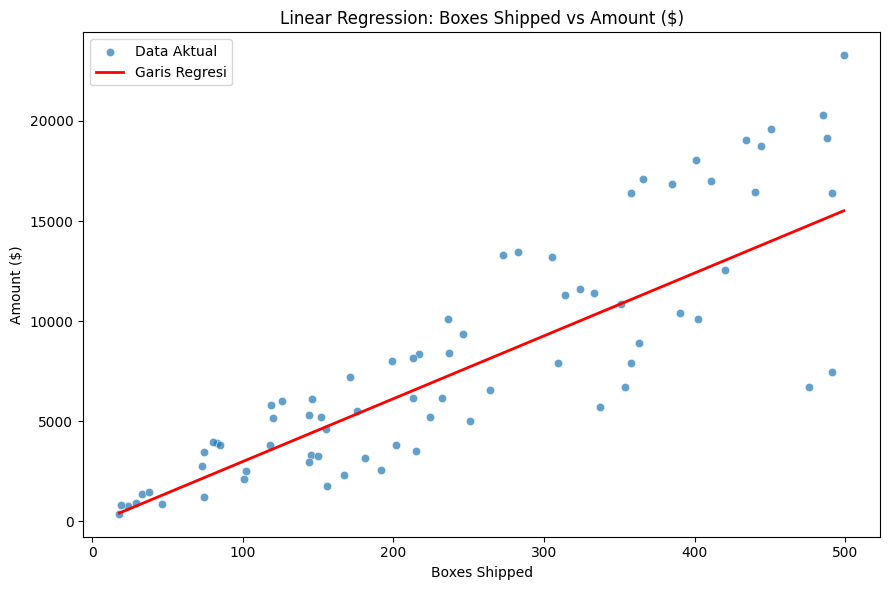

In [12]:
# 202431176_Erika Rahmadina
# Scatter plot data aktual dan garis regresi
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_test['Boxes Shipped'],
    y=y_test,
    label='Data Aktual',
    alpha=0.7
)

# Mengurutkan X agar garis regresi tampil dengan benar
urutan = np.argsort(X_test['Boxes Shipped'].values)

plt.plot(
    X_test['Boxes Shipped'].values[urutan],
    y_pred[urutan],
    color='red',
    linewidth=2,
    label='Garis Regresi'
)

plt.title('Linear Regression: Boxes Shipped vs Amount ($)')
plt.xlabel('Boxes Shipped')
plt.ylabel('Amount ($)')
plt.legend()
plt.tight_layout()
plt.show()